In [34]:
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict, train_test_split, cross_validate, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import TargetEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
import time
warnings.filterwarnings("ignore")

size_text = 14   # change this one number to scale all text
plt.rcParams.update({
    'font.size':        size_text,        # base size (text, annotations)
    'axes.titlesize':   size_text + 2,    # subplot titles
    'axes.labelsize':   size_text,        # x and y axis labels
    'xtick.labelsize':  size_text - 2,    # tick numbers
    'ytick.labelsize':  size_text - 2,
    'legend.fontsize':  size_text - 2,
    'figure.titlesize': size_text - 2,    # fig.suptitle
})

df=pd.read_csv("data.csv")

import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict, train_test_split, cross_validate, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import TargetEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
import time
warnings.filterwarnings("ignore")

size_text = 14   # change this one number to scale all text
plt.rcParams.update({
    'font.size':        size_text,        # base size (text, annotations)
    'axes.titlesize':   size_text + 2,    # subplot titles
    'axes.labelsize':   size_text,        # x and y axis labels
    'xtick.labelsize':  size_text - 2,    # tick numbers
    'ytick.labelsize':  size_text - 2,
    'legend.fontsize':  size_text - 2,
    'figure.titlesize': size_text - 2,    # fig.suptitle
})


#load the dataset data.csv
df=pd.read_csv("data.csv")

# --- DATA EXPLORATION/DESCRIPTION ---
column_names = df.columns
print("Column names in the dataset: \n", column_names)
print("Shape of the dataset: \n", df.shape)

# Filtering the missing values
missing_values = df.isnull().sum()
print("Missing values in each column: \n" , missing_values)
print("Double rows for df: \n", df.duplicated().sum())


Column names in the dataset: 
 Index(['Unnamed: 0', 'brand', 'sale_price', 'fuel_type', 'location',
       'vehicle_model', 'mileage', 'year', 'body_style', 'vehicle_condition',
       'gearbox', 'engine_cylinders', 'drive_type', 'color', 'region',
       'vehicle_size', 'title'],
      dtype='str')
Shape of the dataset: 
 (97331, 17)
Missing values in each column: 
 Unnamed: 0               0
brand                 3283
sale_price               0
fuel_type              565
location                 0
vehicle_model          850
mileage                975
year                   275
body_style               0
vehicle_condition    33062
gearbox                529
engine_cylinders     32762
drive_type           20337
color                18581
region                   0
vehicle_size         63418
title                 2082
dtype: int64
Double rows for df: 
 0


Numeric columns in the dataset: 
 Index(['sale_price', 'mileage', 'year'], dtype='str')
Basic statistics of the numerical columns:
          sale_price       mileage          year
count  9.733100e+04  9.635600e+04  97056.000000
mean   5.763063e+04  9.116786e+04   2012.005595
std    1.197861e+07  1.831625e+05      8.475459
min    0.000000e+00  0.000000e+00   1900.000000
25%    6.500000e+03  3.442500e+04   2009.000000
50%    1.499900e+04  7.954000e+04   2014.000000
75%    2.759000e+04  1.271622e+05   2017.000000
max    3.736929e+09  1.000000e+07   2022.000000
Double rows for numerical values: 
 29664
sale_price    14999.0
mileage       79540.0
year           2014.0
dtype: float64
sale_price    7389
mileage        474
year             0
dtype: int64


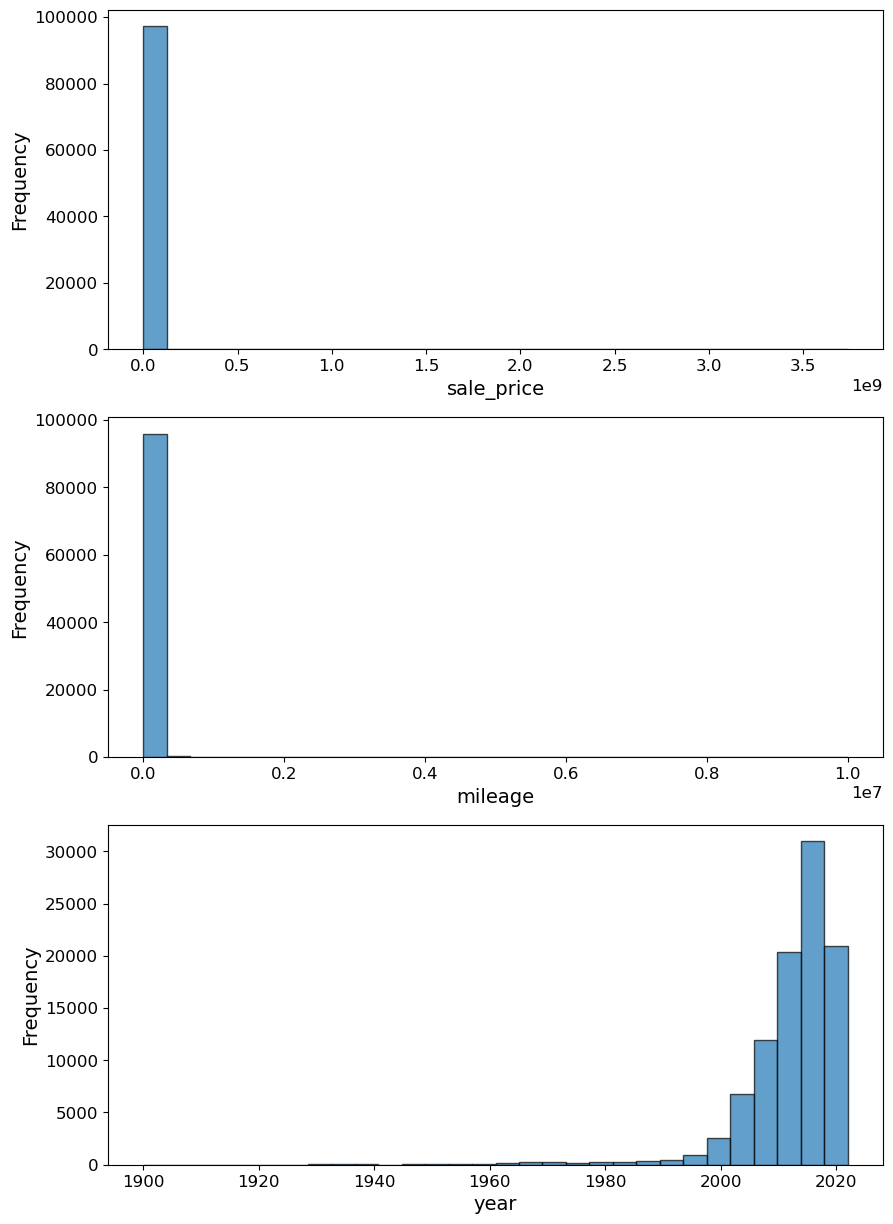

In [35]:
# NUMERICAL COLUMNS
# making correlation matrix with only the numeric columns
numeric_df = df.select_dtypes(include=['float64', 'int64'])
num_cols = numeric_df.columns
# removing the index row called 'Unnamed: 0' (this is the index column)
numeric_df = numeric_df.drop(columns=['Unnamed: 0'])
print("Numeric columns in the dataset: \n", numeric_df.columns)
print("Basic statistics of the numerical columns:\n", numeric_df.describe())
print("Double rows for numerical values: \n", numeric_df.duplicated().sum())
median_rows = numeric_df.median()
print(median_rows)
print((numeric_df == 0).sum())

# Histograms of the numerical values before cleaning with z-score
fig, axes = plt.subplots(nrows=len(numeric_df.columns), ncols=1, figsize=(10, 5 * len(numeric_df.columns)))
for column in numeric_df.columns:
    axes[numeric_df.columns.get_loc(column)].hist(numeric_df[column], bins=30, edgecolor='black', alpha=0.7)
    axes[numeric_df.columns.get_loc(column)].set_xlabel(column)
    axes[numeric_df.columns.get_loc(column)].set_ylabel("Frequency")
plt.savefig("Figures/DataVisualization/histograms_numerical_before.png", dpi=250, bbox_inches="tight")
plt.show()

          feature  n_unique most_frequent  count  percent  n_missing  percent_missing
            title         6         clean  92504    95.04       2082             2.14
        fuel_type         5           gas  80558    82.77        565             0.58
          gearbox         3     automatic  73838    75.86        529             0.54
       drive_type         3           4wd  33838    34.77      20337            20.89
vehicle_condition         6          good  32492    33.38      33062            33.97
       body_style        13         sedan  25542    26.24          0             0.00
 engine_cylinders         8   6 cylinders  24532    25.20      32762            33.66
            color        12         white  20471    21.03      18581            19.09
     vehicle_size         4     full-size  17741    18.23      63418            65.16
            brand        41          ford  15385    15.81       3283             3.37
         location        51            ca  11940    12

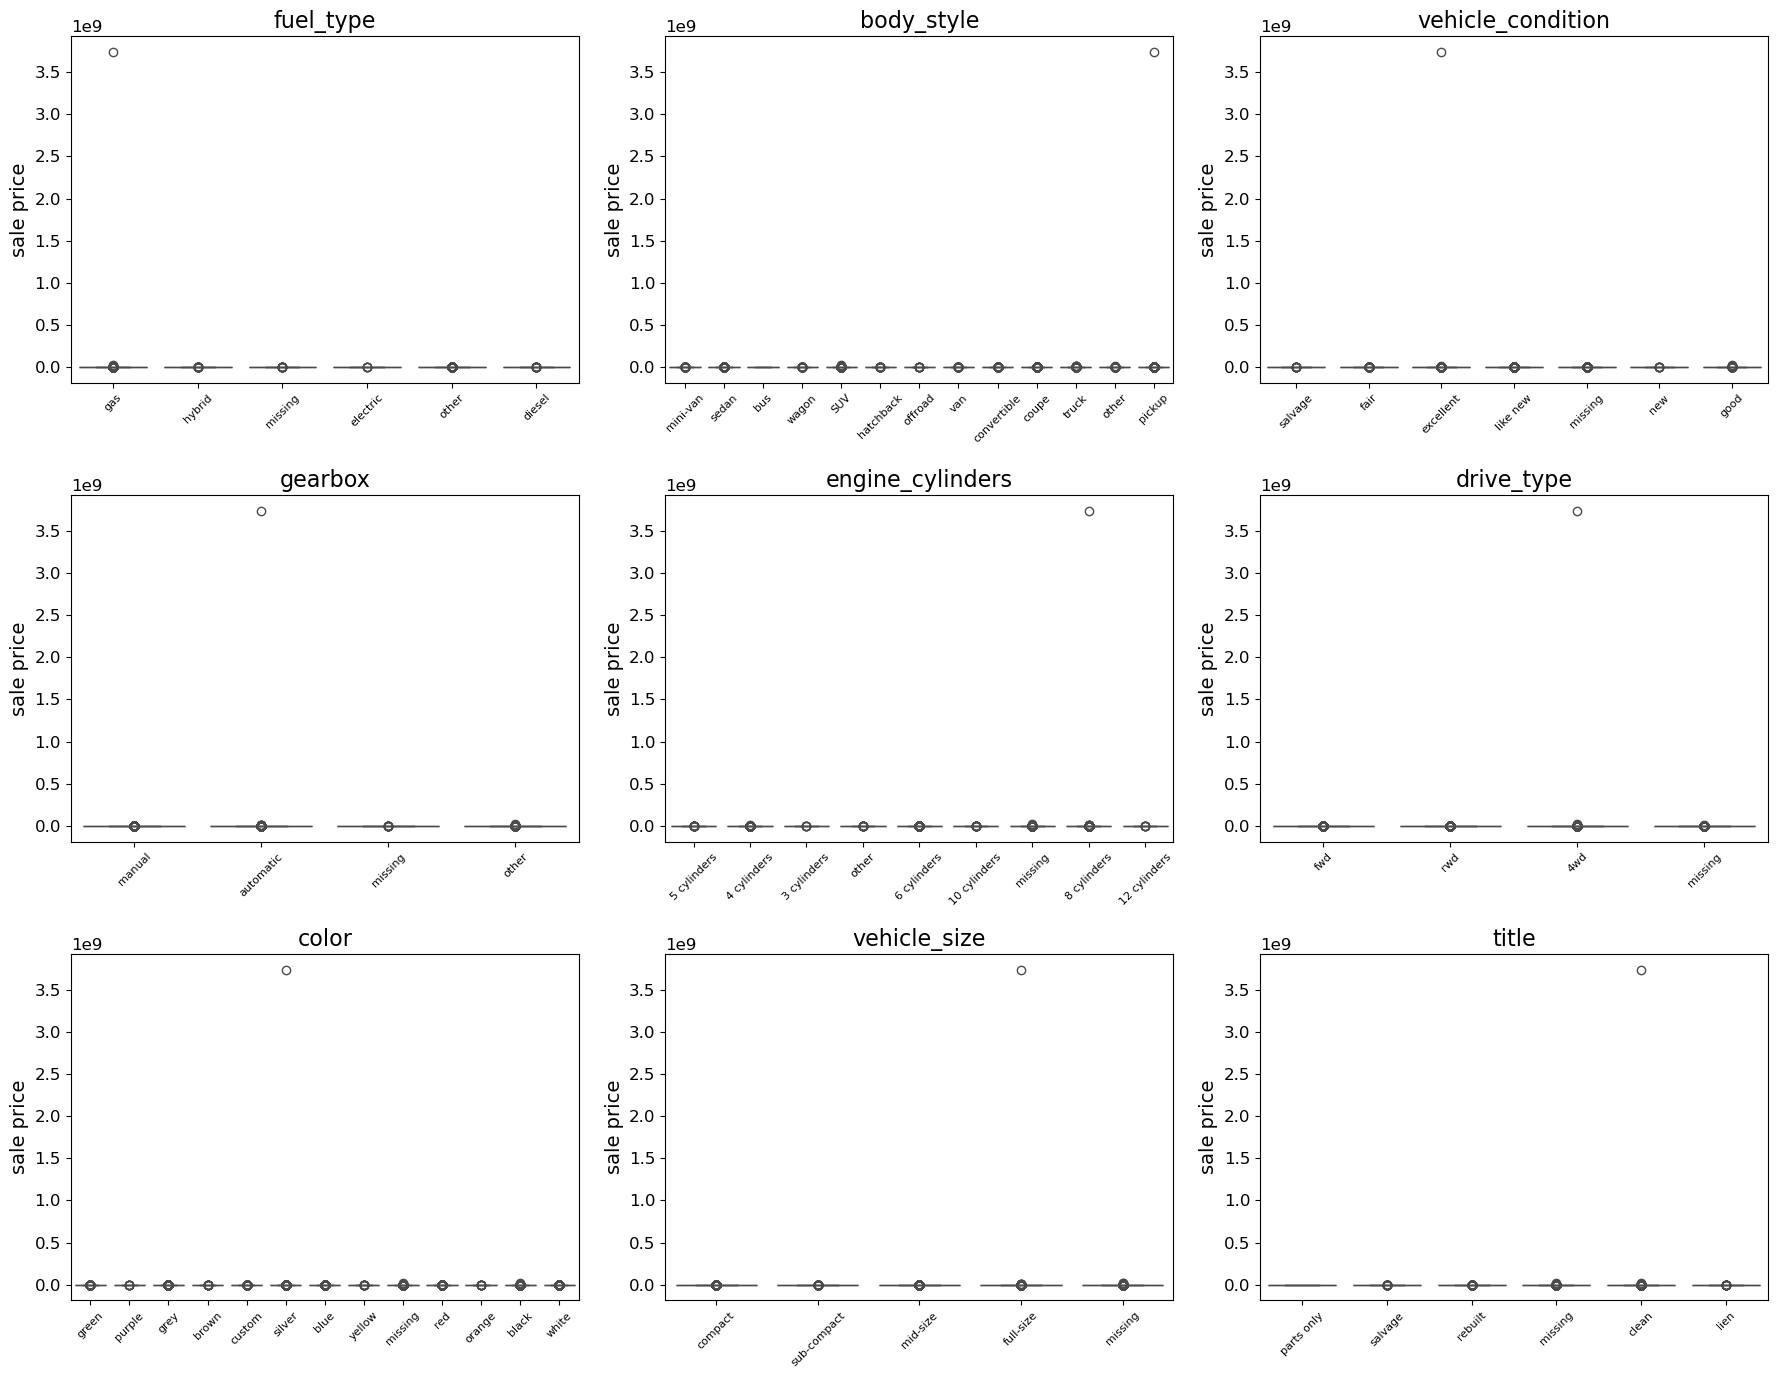

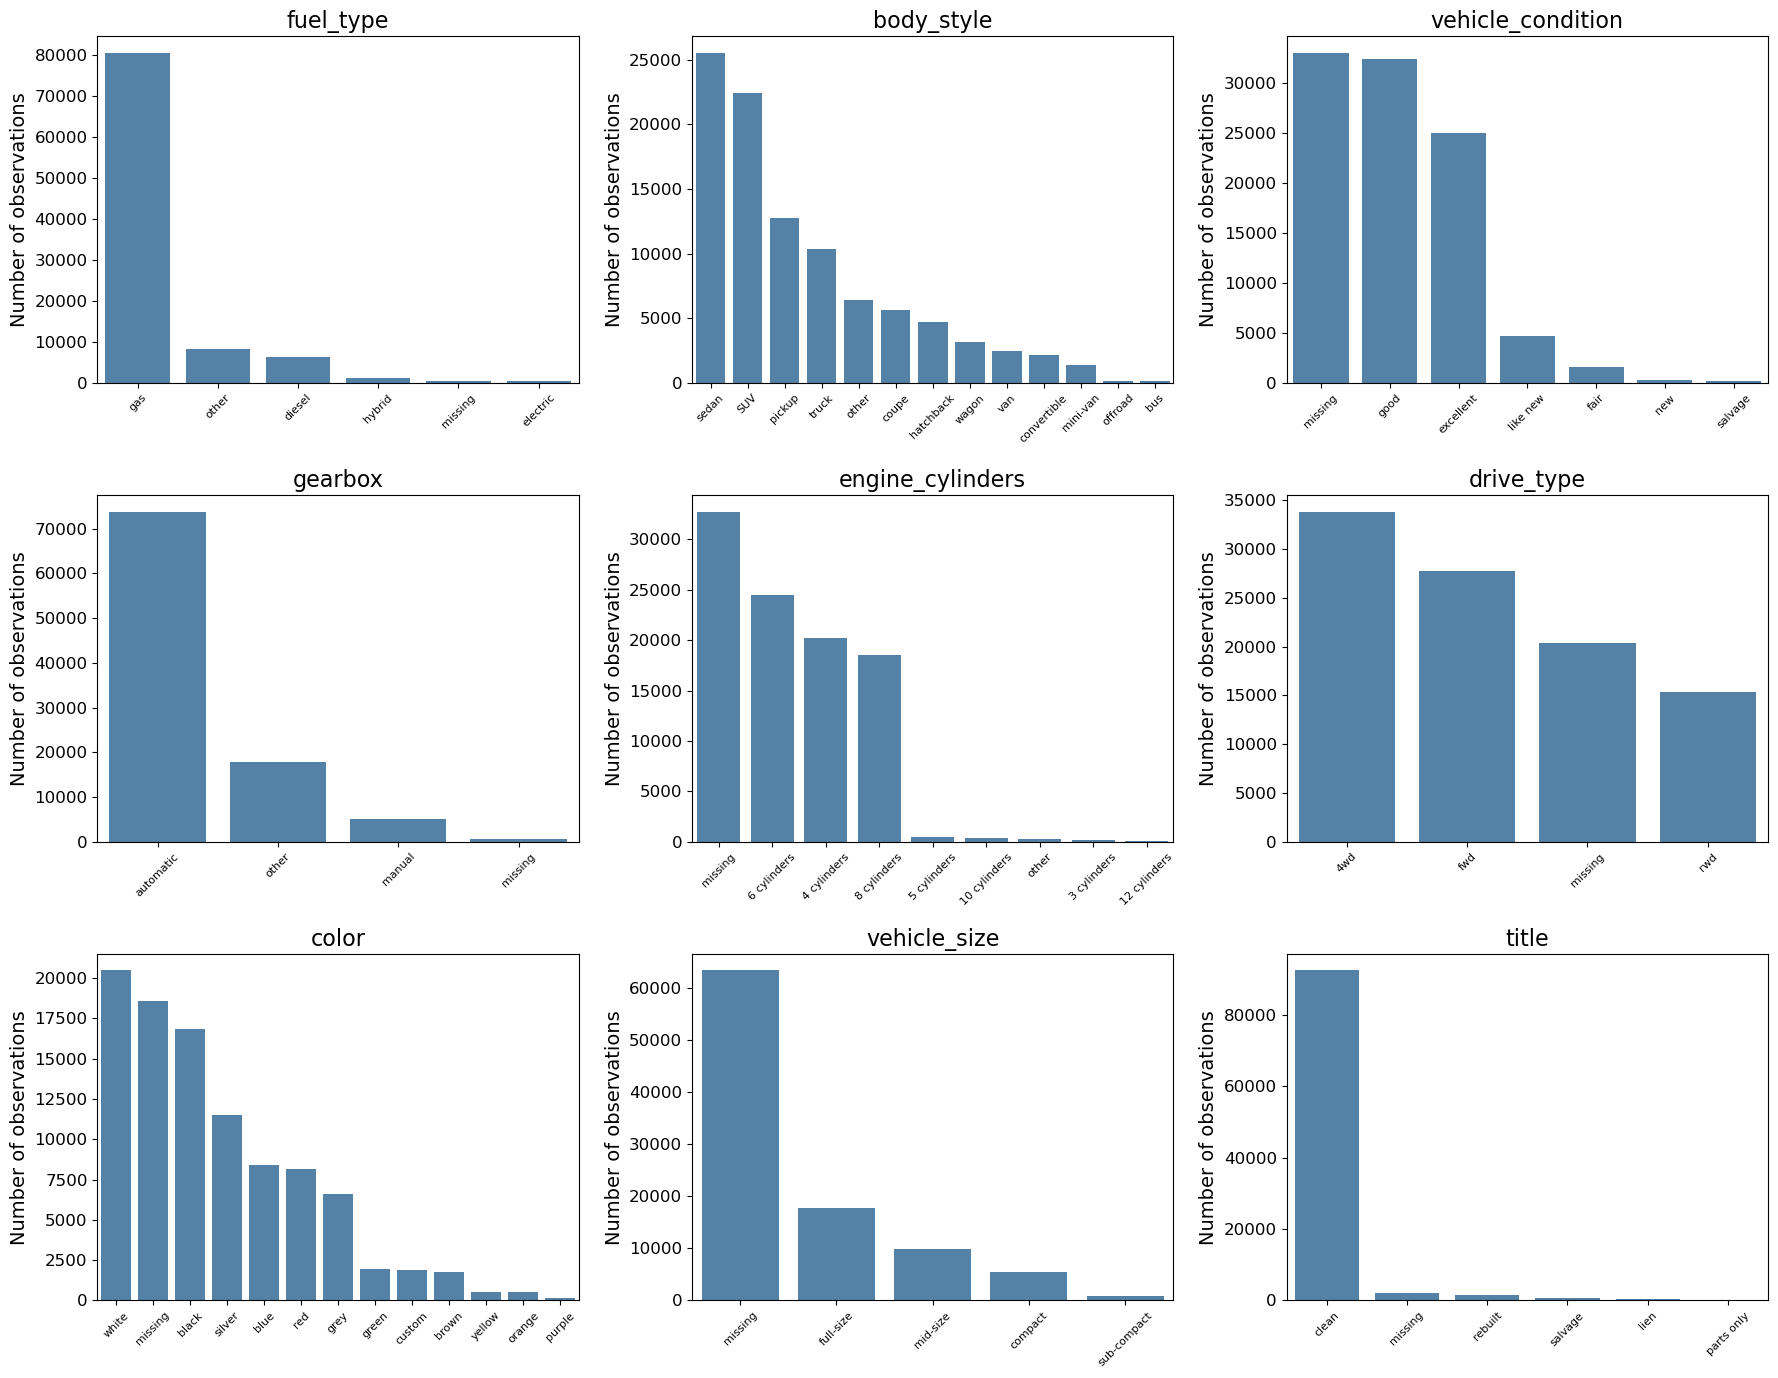

In [36]:
# CATIGORICAL COLUMNS
# Looking at the unique values in the categorical columns
classes_df = df.select_dtypes(include=['object'])
cat_cols = classes_df.columns
classes_df_20 = classes_df.loc[:, classes_df.nunique() <= 20] # Selecting all rows and only the columns with less than or equal to 20 unique values (for shape plot)

rows = []
for col in classes_df.columns:
    counts = df[col].value_counts()          # without NaN here, so the top value is a real category
    n_missing = df[col].isnull().sum()
    top_count = counts.iloc[0]
    rows.append({
        "feature": col,
        "n_unique": df[col].nunique(),
        "most_frequent": counts.index[0],
        "count": top_count,
        "percent": round(top_count / len(df) * 100, 2),
        "n_missing": n_missing,
        "percent_missing": round(n_missing / len(df) * 100, 2),
    })

cat_summary = pd.DataFrame(rows).sort_values("percent", ascending=False)
print(cat_summary.to_string(index=False))
print("Double rows for catagorical values: \n", classes_df.duplicated().sum())

# Boxplot for less than 10 unique values with sales price as target value
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), classes_df_20.columns):
    plot_df = classes_df_20[[col]].copy()               # double brackets: keeps a DataFrame
    plot_df[col] = classes_df_20[col].fillna("missing")   # NaN as its own box
    plot_df["price"] = df["sale_price"]

    # sort boxes by median price
    order = plot_df.groupby(col)["price"].median().sort_values().index

    sns.boxplot(data=plot_df, x=col, y="price", order=order,
                ax=ax, showfliers=True, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("sale price")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/boxplots_before.png", dpi=250, bbox_inches="tight")
plt.show()

# Boxplot for less than 10 unique values with sales price as target value
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), classes_df_20.columns):
    plot_df = classes_df_20[[col]].copy()
    plot_df[col] = plot_df[col].fillna("missing")
    # Sort categories by frequency
    order = plot_df[col].value_counts().index
    sns.countplot(data=plot_df, x=col, order=order, ax=ax, color="steelblue")

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Number of observations")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/histograms_categorical_before.png", dpi=250, bbox_inches="tight")
plt.show()



In [37]:
# --- MISSING VALUES ---
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
n_before = len(df[num_cols])
df = df.drop(columns=["Unnamed: 0"]) # Unnecessary column


0        6 cylinders
1        8 cylinders
2        8 cylinders
3        6 cylinders
4        4 cylinders
            ...     
97326    6 cylinders
97327            NaN
97328    6 cylinders
97329    4 cylinders
97330    8 cylinders
Name: engine_cylinders, Length: 89795, dtype: str


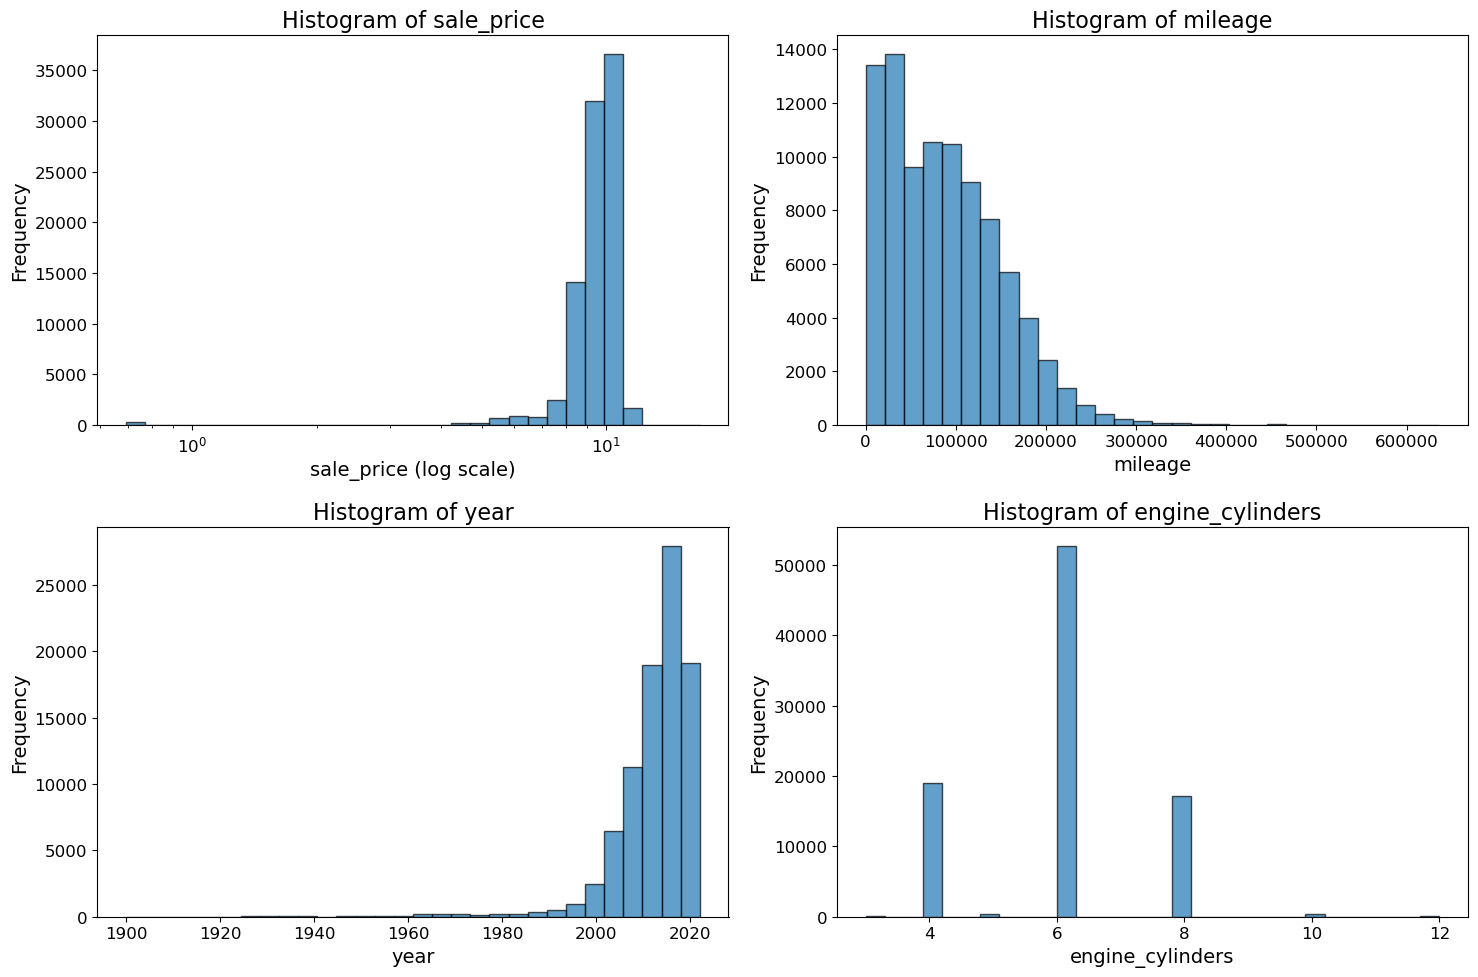

Amount of outliers removed: 
 7536


In [38]:
import math

# -- NUMERICAL DATA PROCESSING --
# -- TARGET_VALUE --
# The target value has best distribution when logscaled 
df['sale_price'] = np.log1p(df['sale_price'])

# -- OUTLIER DETECTION (Z-score) --
z_score_sale_price = (df['sale_price'] - df['sale_price'].mean()) / df['sale_price'].std()
z_score_mileage = (df['mileage'] - df['mileage'].mean()) / df['mileage'].std()
df = df[(np.abs(z_score_sale_price) <= 3) & (np.abs(z_score_mileage) <= 3)].copy()  # Filter out extreme values based on z-score

print(df["engine_cylinders"])
# Converting a catagroical column to a numerical column due to intrinstic order
df["engine_cylinders"] = df["engine_cylinders"].str.extract(r"(\d+)", expand=False).astype(float)
df["engine_cylinders_status"] = np.where(df["engine_cylinders"].isna(), "Unknown", "Known")
df["engine_cylinders"] = df["engine_cylinders"].fillna(df["engine_cylinders"].median())

# Histograms of the numerical values after cleaning with z-score
numeric_df_after = df.select_dtypes(include=['float64', 'int64'])
n_after = len(numeric_df_after)
n = len(numeric_df_after.columns)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5 * nrows))
axes = np.atleast_1d(axes).flatten()      # must come BEFORE the loop

for i, column in enumerate(numeric_df_after.columns):
    ax = axes[i]
    data = numeric_df_after[column].dropna()

    if column == 'sale_price':
        data = data[data > 0]                       # log scale can't show 0
        bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 31)
        ax.hist(data, bins=bins, edgecolor='black', alpha=0.7)
        ax.set_xscale('log')
        ax.set_xlabel(f"{column} (log scale)")
    else:
        ax.hist(data, bins=30, edgecolor='black', alpha=0.7)
        ax.set_xlabel(column)

    ax.set_title(f"Histogram of {column}")
    ax.set_ylabel("Frequency")

# hide unused cells
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/histograms_numerical_after.png", dpi=250, bbox_inches="tight")
plt.show()

print("Amount of outliers removed: \n", n_before - n_after)

                feature  n_unique most_frequent  count  percent  n_missing  percent_missing
                  title         6         clean  85023    94.69          0              0.0
              fuel_type         6           gas  74651    83.13          0              0.0
                gearbox         4     automatic  67011    74.63          0              0.0
engine_cylinders_status         2         Known  60179    67.02          0              0.0
           vehicle_size         5       missing  58656    65.32          0              0.0
      vehicle_condition         7          good  31814    35.43          0              0.0
             drive_type         4           4wd  30970    34.49          0              0.0
             body_style        13         sedan  23582    26.26          0              0.0
                  color        13         white  18774    20.91          0              0.0
                  brand        42          ford  13961    15.55          0      

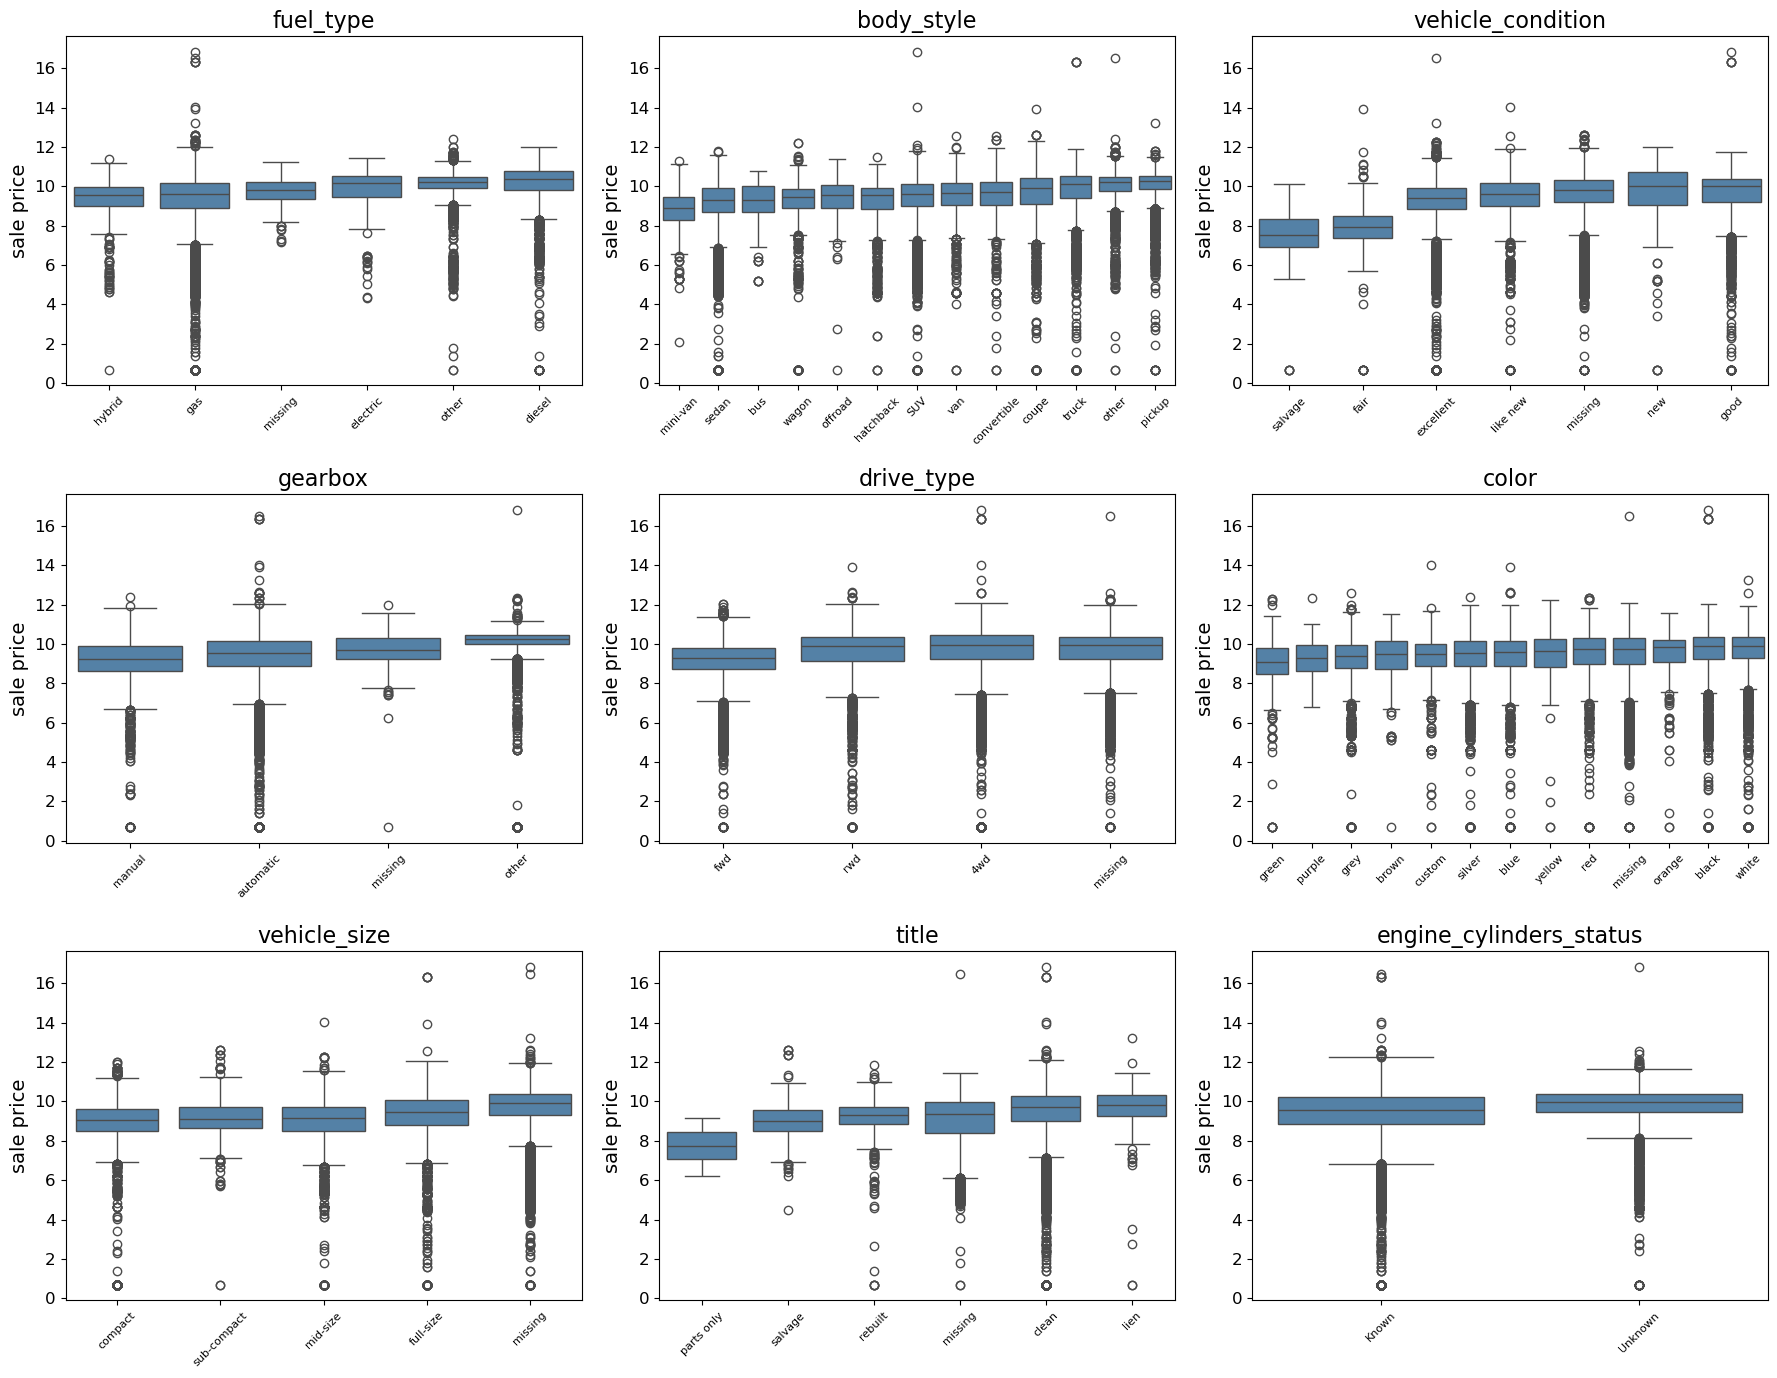

In [39]:
# -- CATIGORICAL COLUMNS --
df[cat_cols] = df[cat_cols].fillna("missing")

# Looking at the unique values in the categorical columns
classes_df = df.select_dtypes(include=['object'])
cat_cols = classes_df.columns
classes_df_20 = classes_df.loc[:, classes_df.nunique() <= 20] # Selecting all rows and only the columns with less than or equal to 20 unique values (for shape plot)

rows = []
for col in classes_df.columns:
    counts = df[col].value_counts()          # without NaN here, so the top value is a real category
    n_missing = df[col].isnull().sum()
    top_count = counts.iloc[0]
    rows.append({
        "feature": col,
        "n_unique": df[col].nunique(),
        "most_frequent": counts.index[0],
        "count": top_count,
        "percent": round(top_count / len(df) * 100, 2),
        "n_missing": n_missing,
        "percent_missing": round(n_missing / len(df) * 100, 2),
    })

cat_summary = pd.DataFrame(rows).sort_values("percent", ascending=False)
print(cat_summary.to_string(index=False))
print("Double rows for catagorical values: \n", classes_df.duplicated().sum())

# Boxplot for less than 10 unique values with sales price as target value
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), classes_df_20.columns):
    plot_df = classes_df_20[[col]].copy()               # double brackets: keeps a DataFrame
    plot_df[col] = classes_df_20[col].fillna("missing")   # NaN as its own box
    plot_df["price"] = df["sale_price"]

    # sort boxes by median price
    order = plot_df.groupby(col)["price"].median().sort_values().index

    sns.boxplot(data=plot_df, x=col, y="price", order=order,
                ax=ax, showfliers=True, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("sale price")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/boxplots_after.png", dpi=250, bbox_inches="tight")
plt.show()


In [40]:
from sklearn.preprocessing import TargetEncoder

num_cols = ["mileage", "year", "engine_cylinders"]
cat_cols_20 = list(classes_df_20.columns)     # the 9 columns with <= 20 categories
catagorical_columns_other = ["brand", "location", "vehicle_model", "region"]

pre = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        ("cat_ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols_20),
        ("cat_te", TargetEncoder(), catagorical_columns_other )
        
    ],
    remainder="drop",    # brand, location, vehicle_model, region are left out for now
)

vehicle_model           0.525832
mileage                -0.396763
year                    0.312979
gearbox_other           0.262571
region                  0.243976
vehicle_size_missing    0.233594
brand                   0.233001
drive_type_fwd         -0.213229
fuel_type_gas          -0.208538
gearbox_automatic      -0.202368
dtype: float64


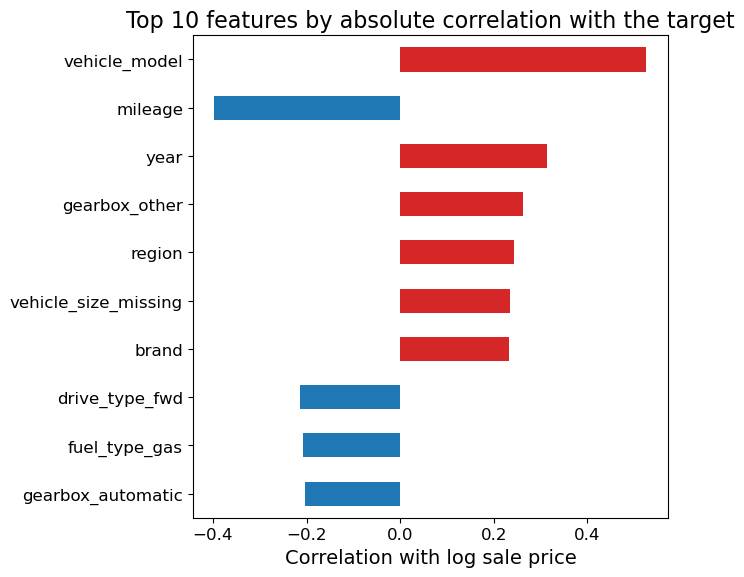

In [41]:
import pandas as pd
import matplotlib.pyplot as plt


X = df.drop(columns=["sale_price"])
y = df["sale_price"]

# encode the whole dataset with the same ColumnTransformer
X_enc = pre.fit_transform(X, y)
if hasattr(X_enc, "toarray"):          # sparse -> dense
    X_enc = X_enc.toarray()

feature_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
enc_df = pd.DataFrame(X_enc, columns=feature_names, index=X.index)

# correlation of every feature with the (log) target, ranked by absolute value
target_corr = enc_df.corrwith(y).sort_values(key=abs, ascending=False)
print(target_corr.head(10))

top = target_corr.head(10)[::-1]
plt.figure(figsize=(7, 6))
top.plot.barh(color=["tab:blue" if v < 0 else "tab:red" for v in top])
plt.xlabel("Correlation with log sale price")
plt.title("Top 10 features by absolute correlation with the target")
plt.tight_layout()
plt.savefig("Figures/DataVisualization/target_correlation.png", dpi=250, bbox_inches="tight")
plt.show()

In [42]:
"""# Histograms of the numerical values after cleaning with z-score
numeric_df_after = df.select_dtypes(include=['float64', 'int64'])

n = len(numeric_df_after.columns)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5 * nrows))
axes = np.atleast_1d(axes).flatten()      # must come BEFORE the loop

for i, column in enumerate(numeric_df_after.columns):
    ax = axes[i]
    data = numeric_df_after[column].dropna()

    if column == 'sale_price':
        data = data[data > 0]                       # log scale can't show 0
        bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 31)
        ax.hist(data, bins=bins, edgecolor='black', alpha=0.7)
        ax.set_xscale('log')
        ax.set_xlabel(f"{column} (log scale)")
    else:
        ax.hist(data, bins=30, edgecolor='black', alpha=0.7)
        ax.set_xlabel(column)

    ax.set_title(f"Histogram of {column}")
    ax.set_ylabel("Frequency")

# hide unused cells
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/histograms_numerical_after.png", dpi=300)
plt.show()

correlation_matrix = numeric_df_after.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.savefig("Figures/correlation_matrix_numerical_after.png")
"""


'# Histograms of the numerical values after cleaning with z-score\nnumeric_df_after = df.select_dtypes(include=[\'float64\', \'int64\'])\n\nn = len(numeric_df_after.columns)\nncols = 2\nnrows = math.ceil(n / ncols)\n\nfig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5 * nrows))\naxes = np.atleast_1d(axes).flatten()      # must come BEFORE the loop\n\nfor i, column in enumerate(numeric_df_after.columns):\n    ax = axes[i]\n    data = numeric_df_after[column].dropna()\n\n    if column == \'sale_price\':\n        data = data[data > 0]                       # log scale can\'t show 0\n        bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 31)\n        ax.hist(data, bins=bins, edgecolor=\'black\', alpha=0.7)\n        ax.set_xscale(\'log\')\n        ax.set_xlabel(f"{column} (log scale)")\n    else:\n        ax.hist(data, bins=30, edgecolor=\'black\', alpha=0.7)\n        ax.set_xlabel(column)\n\n    ax.set_title(f"Histogram of {column}")\n    ax.set_ylabel("Frequ

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
import pandas as pd
import matplotlib.pyplot as plt

num_cols = ["mileage", "year", "engine_cylinders"]

cat_cols_20 = [
    col for col in classes_df_20.columns
    if col != "body_style"
]

catagorical_columns_other = [
    "brand", "location", "vehicle_model", "region"
]

pre = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),

        ("cat_ohe",
         OneHotEncoder(
             handle_unknown="ignore",
             drop="if_binary"
         ),
         cat_cols_20),

        ("cat_te",
         TargetEncoder(
             target_type="multiclass",
             smooth="auto",
             cv=5,
             shuffle=True,
             random_state=42
         ),
         catagorical_columns_other)
    ],
    remainder="drop"
)

In [44]:
X = df.drop(columns=["body_style"])
y = df["body_style"]

X_enc = pre.fit_transform(X, y)

if hasattr(X_enc, "toarray"):
    X_enc = X_enc.toarray()

feature_names = [
    n.split("__", 1)[1]
    for n in pre.get_feature_names_out()
]

enc_df = pd.DataFrame(
    X_enc,
    columns=feature_names,
    index=X.index
)

In [45]:
target_corr = {}

for category in y.unique():

    y_binary = (y == category).astype(int)

    target_corr[category] = (
        enc_df.corrwith(y_binary)
        .sort_values(key=abs, ascending=False)
    )

    print(f"\nTop 10 features for {category}:")
    print(target_corr[category].head(10))


Top 10 features for pickup:
vehicle_model_pickup    0.784745
brand_pickup            0.430934
brand_truck             0.412476
brand_sedan            -0.308903
vehicle_model_truck     0.256232
vehicle_model_sedan    -0.245413
engine_cylinders        0.230494
drive_type_4wd          0.229654
vehicle_model_SUV      -0.227348
drive_type_fwd         -0.217838
dtype: float64

Top 10 features for convertible:
vehicle_model_convertible    0.660919
brand_convertible            0.198605
drive_type_rwd               0.186041
year                        -0.162431
gearbox_manual               0.116260
drive_type_4wd              -0.095104
brand_coupe                  0.093368
vehicle_size_sub-compact     0.089812
vehicle_model_coupe          0.082961
brand_other                  0.074299
dtype: float64

Top 10 features for mini-van:
vehicle_model_mini-van    0.658516
vehicle_model_van         0.252412
brand_mini-van            0.246317
brand_van                 0.173606
drive_type_fwd            

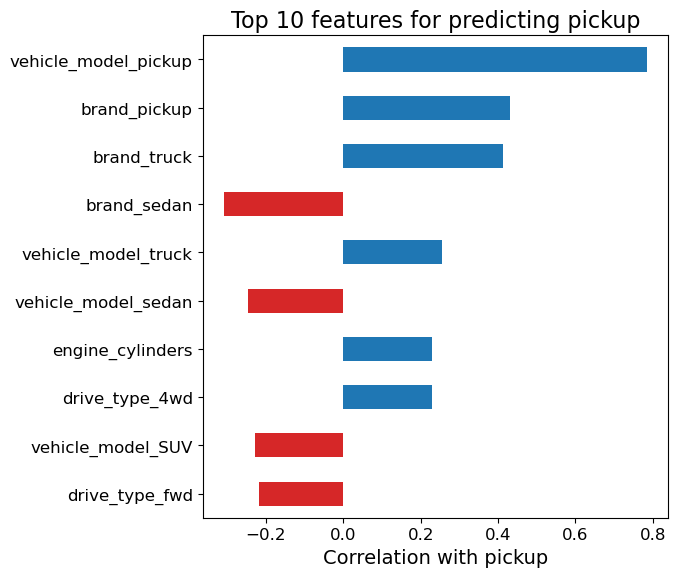

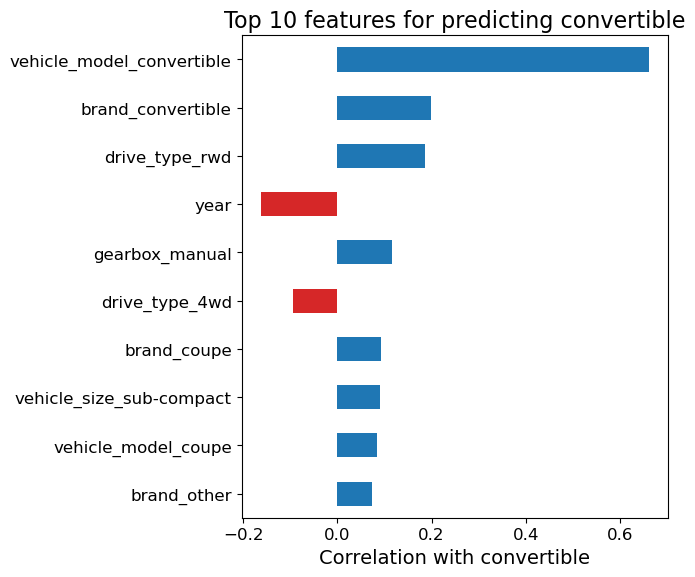

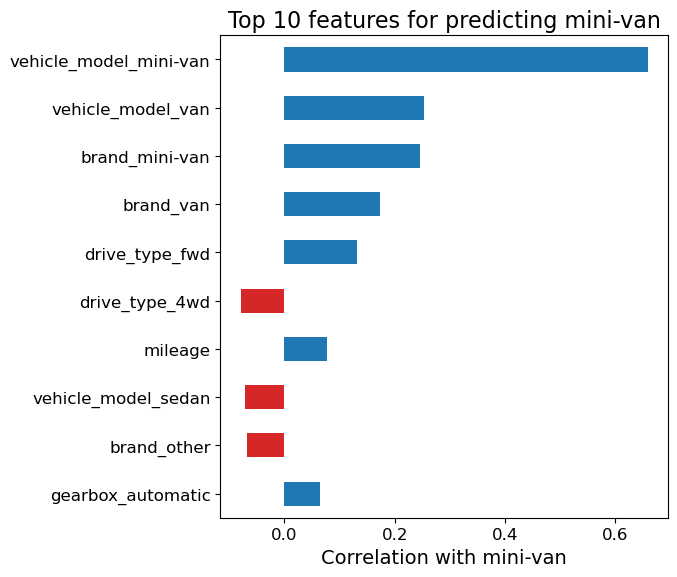

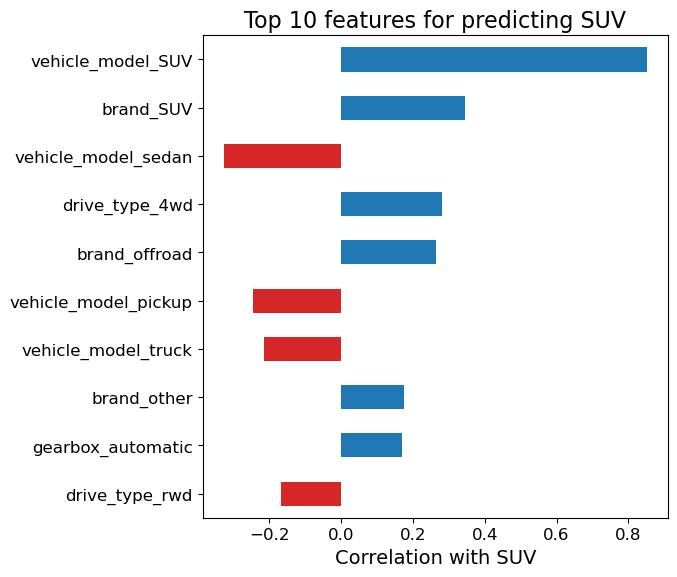

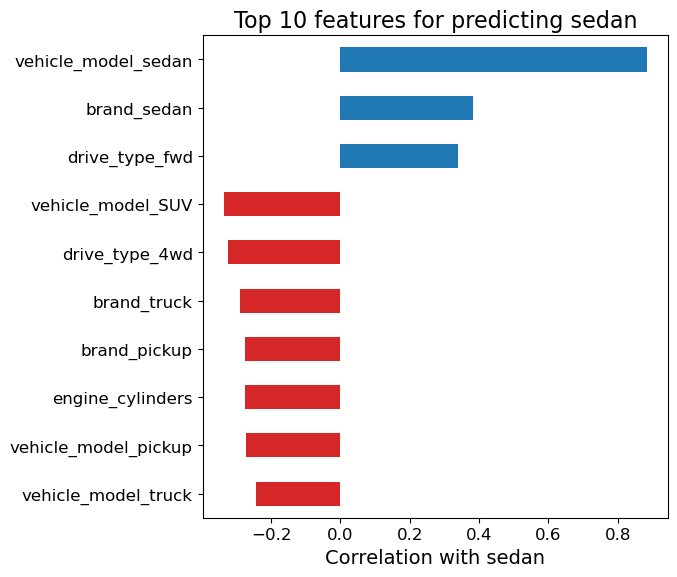

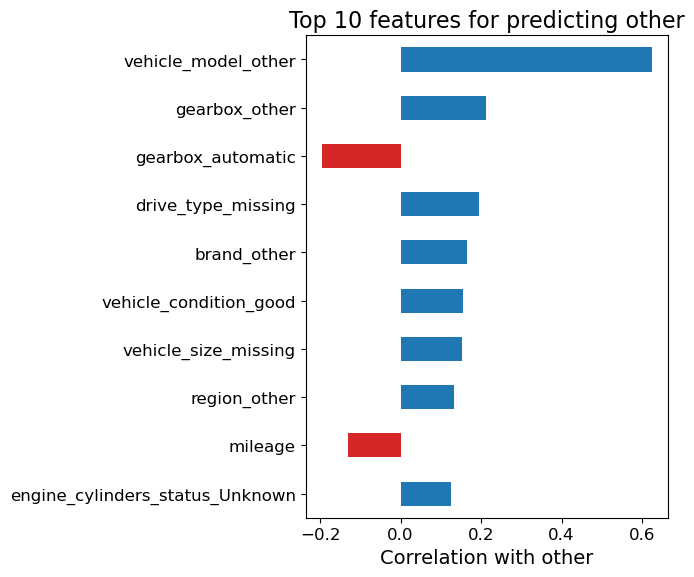

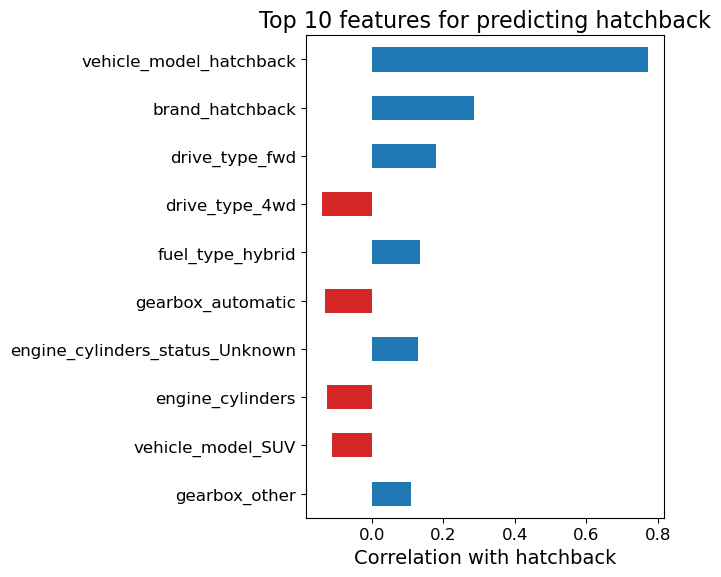

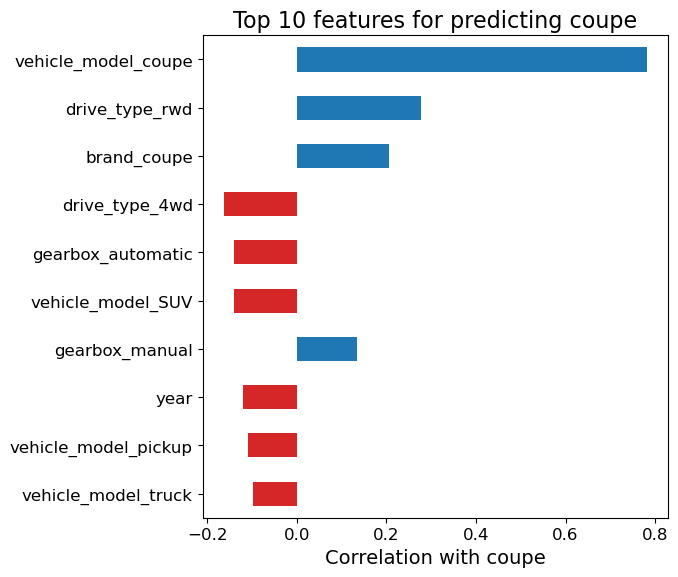

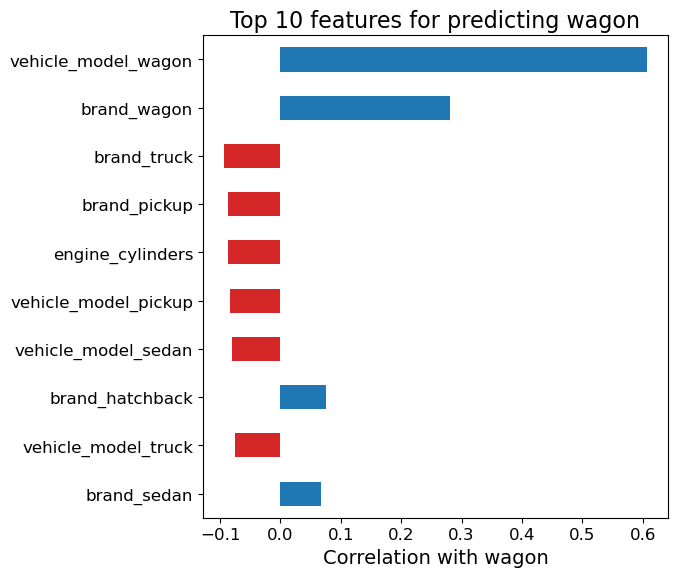

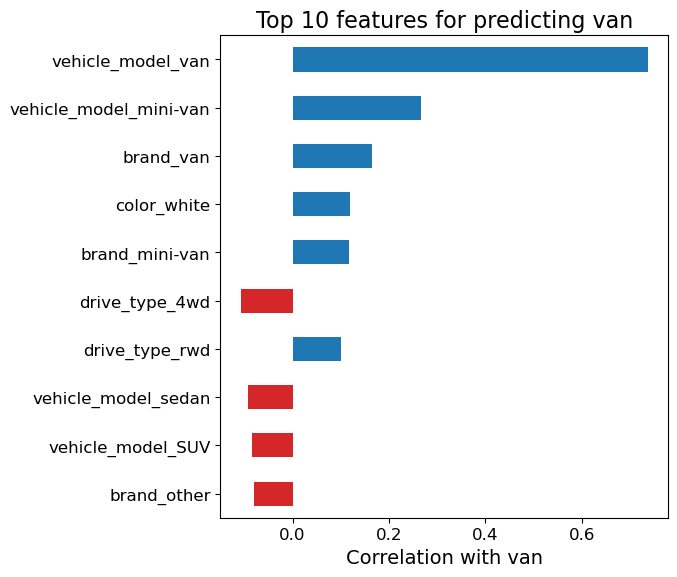

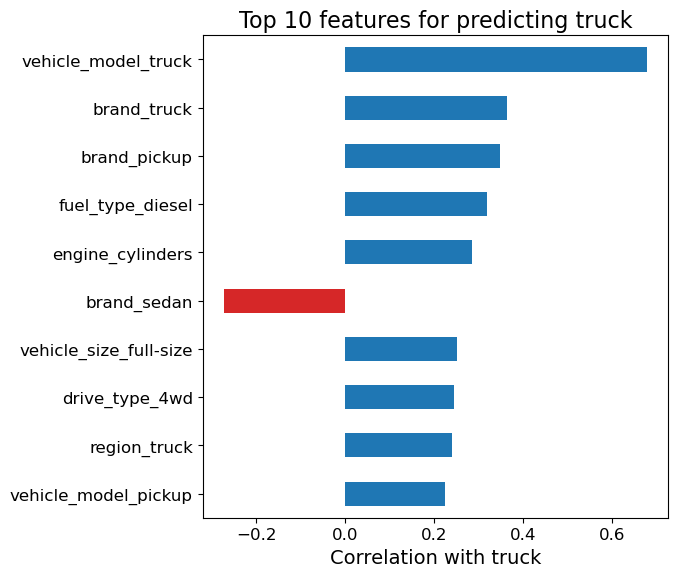

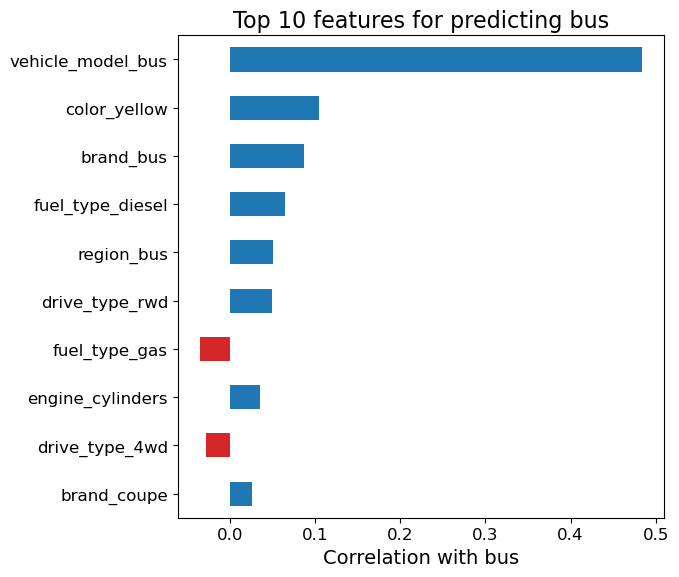

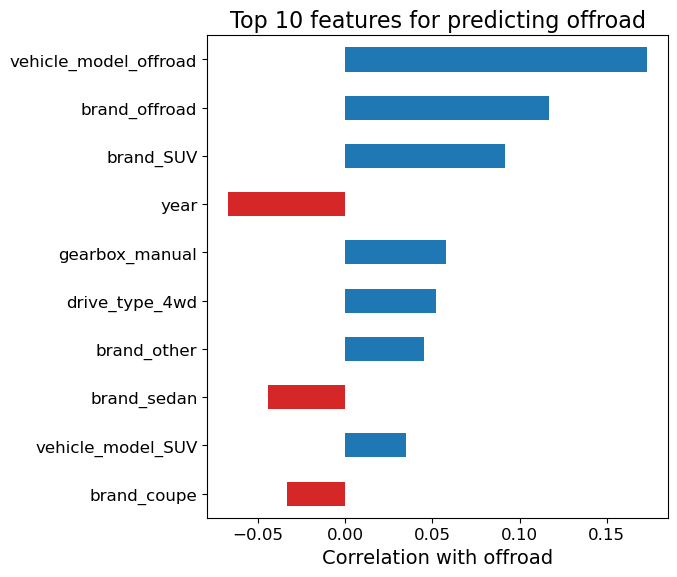

In [46]:
for category in y.unique():

    top = target_corr[category].head(10)[::-1]

    plt.figure(figsize=(7, 6))

    top.plot.barh(
        color=[
            "tab:red" if v < 0 else "tab:blue"
            for v in top
        ]
    )

    plt.xlabel(f"Correlation with {category}")
    plt.title(f"Top 10 features for predicting {category}")

    plt.tight_layout()
    plt.show()